# Titanic Survival Prediction
**Omar Hamad Al-Nasser** · Machine learning project, first built during my co-op at Saudi Global Ports (SGP), rebuilt November 2026

**Question:** who was most likely to survive the Titanic, and how well can a model predict it from the passenger list?

**What changed in this version**
- **Real data.** The first version used a synthetic copy of the dataset (invented names, a 57% survival rate instead of the real 38%), which capped accuracy at about 65%. This version uses the original Kaggle *Titanic: Machine Learning from Disaster* files (891 labelled passengers, 418 test passengers).
- **No leakage.** Missing ages and fares are filled inside the model pipeline, so every cross-validation fold only learns from its own training rows.
- **Fair comparison.** Four models are compared with 5-fold cross-validation repeated 3 times, not one random split.
- **Honest evaluation.** The final model is checked on a 20% hold-out set it never saw, with a confusion matrix, ROC curve and permutation importance.

| Step | What happens |
|---|---|
| 1 | Load and check the data |
| 2 | Explore who survived |
| 3 | Engineer features |
| 4 | Compare four models with cross-validation |
| 5 | Tune the best model and evaluate on the hold-out set |
| 6 | Explain the model and write the Kaggle submission |
| 7 | Summary for a non-technical reader |

In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import GradientBoostingClassifier, RandomForestClassifier, VotingClassifier
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (ConfusionMatrixDisplay, RocCurveDisplay, accuracy_score,
                             classification_report, roc_auc_score)
from sklearn.model_selection import GridSearchCV, RepeatedStratifiedKFold, cross_validate, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.svm import SVC

from titanic_lib import CATEGORICAL, NUMERIC, GroupImputer, add_features

warnings.filterwarnings('ignore')
SEED = 42
PALETTE = {'died': '#B0B7C3', 'survived': '#6C4BD8', 'accent': '#E07A5F', 'ink': '#1F2430'}
sns.set_theme(style='white', font_scale=1.0)
plt.rcParams.update({'figure.dpi': 120, 'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.titleweight': 'bold', 'axes.titlesize': 13})

## 1 · Load and check the data

In [2]:
train = pd.read_csv('data/train.csv')
test = pd.read_csv('data/test.csv')
print(f'Train: {train.shape[0]} passengers, {train.shape[1]} columns')
print(f'Test:  {test.shape[0]} passengers (no Survived column; scored by Kaggle)')
print(f'Overall survival rate: {train.Survived.mean():.1%}')
train.head()

Train: 891 passengers, 12 columns
Test:  418 passengers (no Survived column; scored by Kaggle)
Overall survival rate: 38.4%


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [3]:
missing = pd.concat([train.isna().sum(), test.isna().sum()], axis=1, keys=['train', 'test'])
missing['train %'] = (missing['train'] / len(train) * 100).round(1)
missing[missing[['train', 'test']].sum(axis=1) > 0].sort_values('train', ascending=False)

,train,test,train %
Cabin,687,327.0,77.1
Age,177,86.0,19.9
Embarked,2,0.0,0.2
Fare,0,1.0,0.0


**Missing values and how they are handled**
- **Cabin (77% missing):** too sparse to impute, but *whether* a cabin was recorded is informative, so it becomes `HasCabin` and a `Deck` letter (U = unknown).
- **Age (20% missing):** filled with the median age for the passenger's title and class (a *Master* is a boy, a *Mrs* is an adult woman). The median is learned inside each training fold. A flag `AgeMissing` keeps the fact that it was unknown.
- **Embarked (2 rows):** filled with the most common port, Southampton.
- **Fare (1 test row):** filled with the median fare for that class.

## 2 · Explore who survived

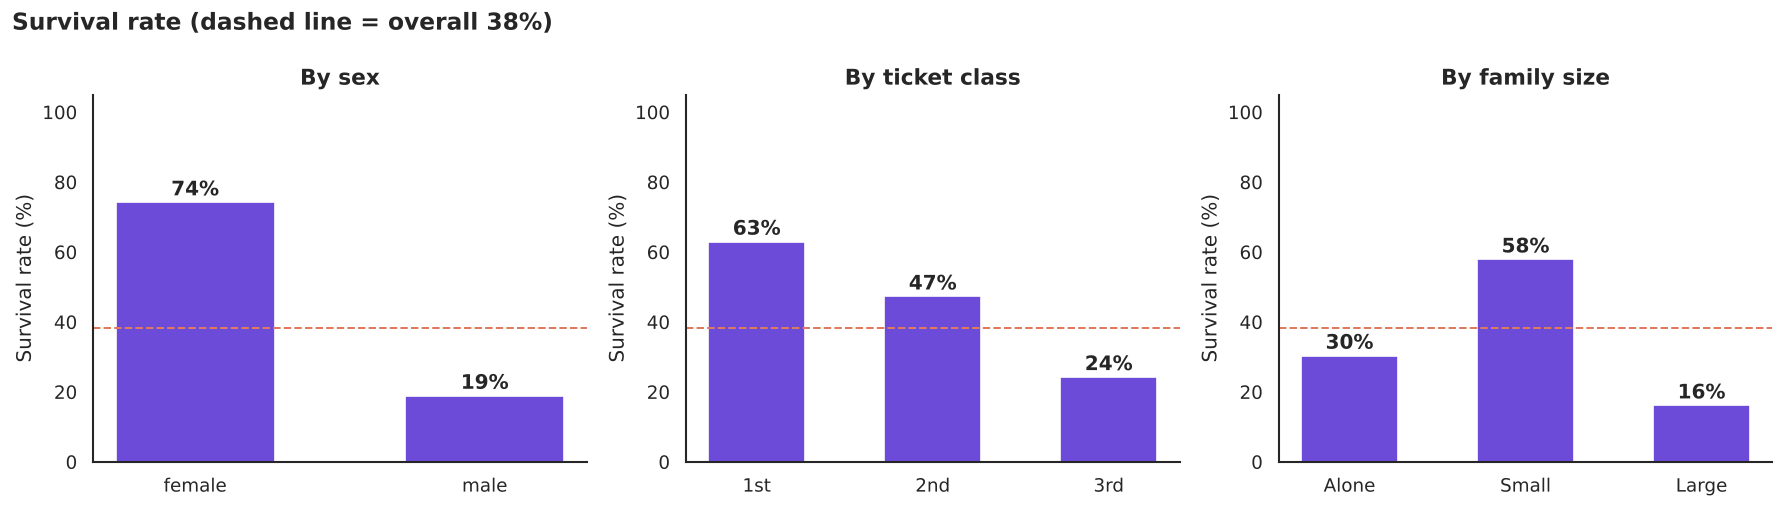

In [4]:
def rate_bar(ax, series, title, order=None):
    s = series.reindex(order) if order else series
    bars = ax.bar(s.index.astype(str), s.values * 100, color=PALETTE['survived'], width=0.55)
    ax.axhline(train.Survived.mean() * 100, color=PALETTE['accent'], ls='--', lw=1.2)
    for b, v in zip(bars, s.values):
        ax.text(b.get_x() + b.get_width() / 2, v * 100 + 2, f'{v:.0%}', ha='center', fontweight='bold')
    ax.set_ylim(0, 105); ax.set_ylabel('Survival rate (%)'); ax.set_title(title)

eda = add_features(train)
fig, axes = plt.subplots(1, 3, figsize=(15, 4.3))
rate_bar(axes[0], train.groupby('Sex').Survived.mean(), 'By sex', ['female', 'male'])
rate_bar(axes[1], train.groupby('Pclass').Survived.mean().rename(index={1: '1st', 2: '2nd', 3: '3rd'}), 'By ticket class')
rate_bar(axes[2], eda.groupby('FamilyType').Survived.mean(), 'By family size', ['Alone', 'Small', 'Large'])
fig.suptitle('Survival rate (dashed line = overall 38%)', x=0.01, ha='left', fontsize=14, fontweight='bold')
plt.tight_layout(); plt.savefig('images/01_survival_rates.png', bbox_inches='tight'); plt.show()

- **Sex was the strongest factor:** 74% of women survived against 19% of men ("women and children first").
- **Class mattered:** 63% of first-class passengers survived, 24% of third class.
- **Small families did best:** travelling alone or in a family of five or more both lowered the odds.

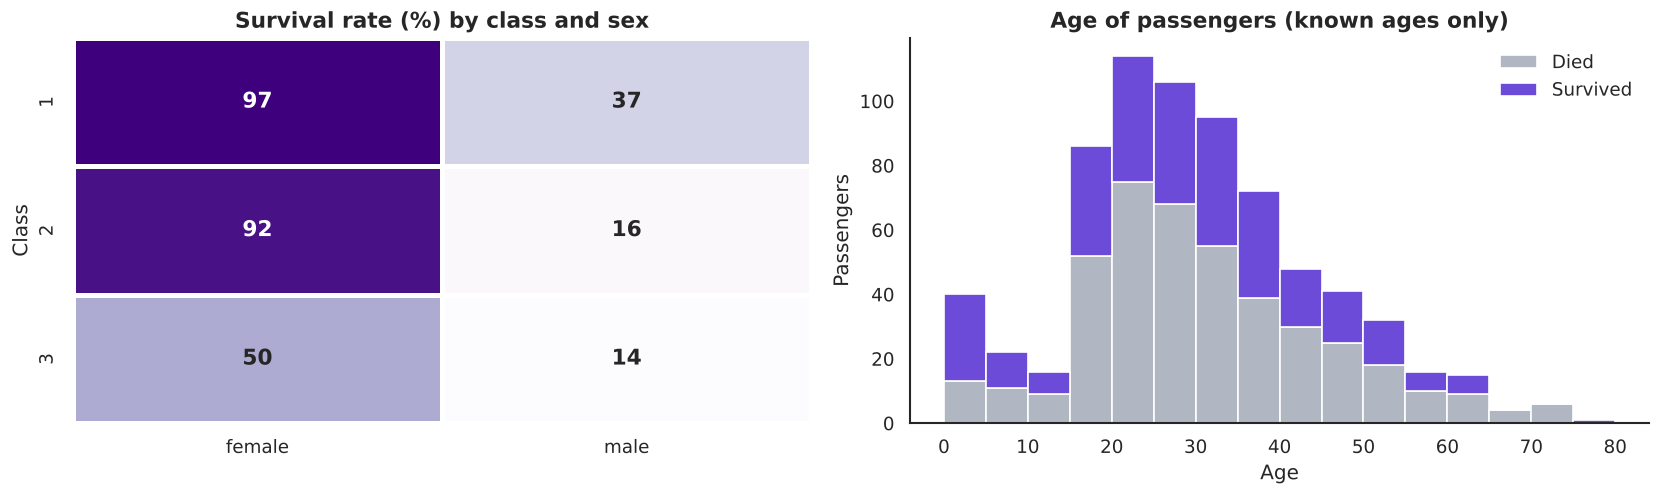

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.3))
ct = pd.crosstab([train.Pclass, train.Sex], train.Survived, normalize='index')[1].unstack()
sns.heatmap(ct * 100, annot=True, fmt='.0f', cmap='Purples', cbar=False, ax=axes[0],
            annot_kws={'size': 13, 'weight': 'bold'}, linewidths=2, linecolor='white')
axes[0].set_title('Survival rate (%) by class and sex'); axes[0].set_ylabel('Class'); axes[0].set_xlabel('')
age = train.dropna(subset=['Age'])
axes[1].hist([age.loc[age.Survived == 0, 'Age'], age.loc[age.Survived == 1, 'Age']], bins=range(0, 85, 5),
             stacked=True, color=[PALETTE['died'], PALETTE['survived']], label=['Died', 'Survived'], edgecolor='white')
axes[1].set_title('Age of passengers (known ages only)'); axes[1].set_xlabel('Age'); axes[1].set_ylabel('Passengers')
axes[1].legend(frameon=False)
plt.tight_layout(); plt.savefig('images/02_class_sex_age.png', bbox_inches='tight'); plt.show()

- **Class and sex together explain most of the story:** 97% of first-class women survived; 14% of third-class men did.
- **Children under about 10 survived more often** than any adult age group.

## 3 · Engineer features

In [6]:
ticket_counts = pd.concat([train.Ticket, test.Ticket]).value_counts()
X = add_features(train.drop(columns='Survived'), ticket_counts)
y = train.Survived
X_kaggle = add_features(test, ticket_counts)

X[['Name', 'Title', 'FamilySize', 'FamilyType', 'Deck', 'HasCabin', 'TicketGroup']].head(8)

,Name,Title,FamilySize,FamilyType,Deck,HasCabin,TicketGroup
0,"Braund, Mr. Owen Harris",Mr,2,Small,U,0,1
1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",Mrs,2,Small,C,1,2
2,"Heikkinen, Miss. Laina",Miss,1,Alone,U,0,1
3,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",Mrs,2,Small,C,1,2
4,"Allen, Mr. William Henry",Mr,1,Alone,U,0,1
5,"Moran, Mr. James",Mr,1,Alone,U,0,1
6,"McCarthy, Mr. Timothy J",Mr,1,Alone,E,1,2
7,"Palsson, Master. Gosta Leonard",Master,5,Large,U,0,5


| Feature | Built from | Why it helps |
|---|---|---|
| `Title` | Name (Mr, Mrs, Miss, Master, Rare) | Carries sex, age group and status in one field; *Master* marks boys |
| `FamilySize`, `FamilyType` | SibSp + Parch + 1 | Small families survived more than people alone or in large groups |
| `Deck`, `HasCabin` | Cabin | A recorded cabin signals a better-documented, usually wealthier passenger |
| `TicketGroup` | How many passengers share a ticket | Groups travelled and evacuated together |
| `FarePerPerson` | Fare ÷ TicketGroup, log scale | Fares were per ticket, not per person |
| `IsChild`, `AgeMissing` | Age | Children were prioritised; a missing age is itself informative |

`TicketGroup` counts tickets across the train and test passenger lists. It uses no survival labels, so it does not leak the answer.

## 4 · Compare four models with cross-validation

In [7]:
X_train, X_hold, y_train, y_hold = train_test_split(X, y, test_size=0.2, stratify=y, random_state=SEED)

def make_pipe(model, scale=True):
    encode = ColumnTransformer([
        ('cat', OneHotEncoder(handle_unknown='ignore'), CATEGORICAL),
        ('num', StandardScaler() if scale else 'passthrough', NUMERIC)])
    return Pipeline([('impute', GroupImputer()), ('encode', encode), ('model', model)])

models = {
    'Logistic Regression': make_pipe(LogisticRegression(max_iter=2000, C=0.5)),
    'Random Forest': make_pipe(RandomForestClassifier(n_estimators=500, max_depth=7, min_samples_leaf=2, random_state=SEED), scale=False),
    'Gradient Boosting': make_pipe(GradientBoostingClassifier(n_estimators=300, learning_rate=0.05, max_depth=3, random_state=SEED), scale=False),
    'SVM (RBF)': make_pipe(SVC(C=1.0, probability=True, random_state=SEED)),
}
cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=SEED)
rows = []
for name, pipe in models.items():
    s = cross_validate(pipe, X_train, y_train, cv=cv, scoring=['accuracy', 'roc_auc', 'f1'])
    rows.append({'Model': name, 'Accuracy': s['test_accuracy'].mean(), '± std': s['test_accuracy'].std(),
                 'ROC AUC': s['test_roc_auc'].mean(), 'F1': s['test_f1'].mean()})
cv_results = pd.DataFrame(rows).sort_values('Accuracy', ascending=False).reset_index(drop=True)
cv_results.style.format({c: '{:.3f}' for c in ['Accuracy', '± std', 'ROC AUC', 'F1']}).background_gradient(subset=['Accuracy'], cmap='Purples')

,Model,Accuracy,± std,ROC AUC,F1
0,Random Forest,0.830,0.027,0.880,0.765
1,Logistic Regression,0.828,0.033,0.875,0.773
2,Gradient Boosting,0.827,0.027,0.883,0.766
3,SVM (RBF),0.824,0.026,0.871,0.760


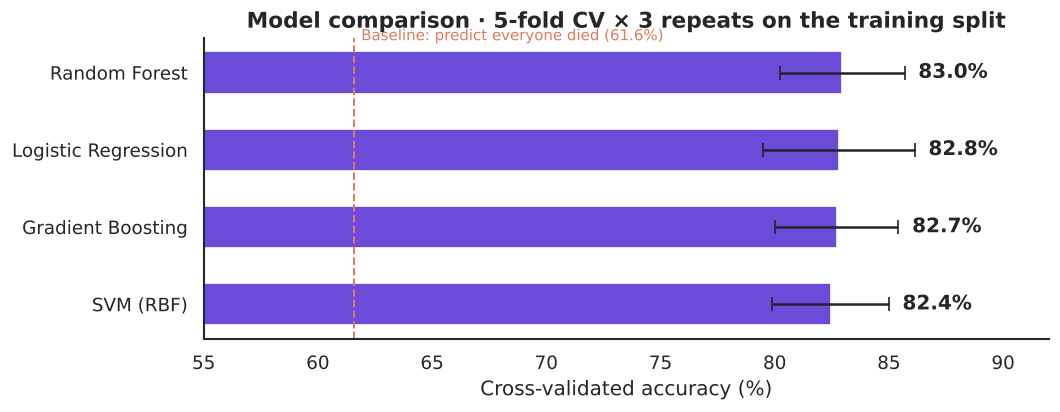

In [8]:
fig, ax = plt.subplots(figsize=(9, 3.6))
order = cv_results.sort_values('Accuracy')
ax.barh(order.Model, order.Accuracy * 100, xerr=order['± std'] * 100, color=PALETTE['survived'], height=0.55,
        error_kw={'ecolor': PALETTE['ink'], 'capsize': 4})
for i, (v, sd) in enumerate(zip(order.Accuracy, order['± std'])):
    ax.text((v + sd) * 100 + 0.6, i, f'{v:.1%}', va='center', fontweight='bold')
ax.axvline(61.6, color=PALETTE['accent'], ls='--', lw=1.2)
ax.text(61.9, 3.42, 'Baseline: predict everyone died (61.6%)', color=PALETTE['accent'], fontsize=9)
ax.set_xlim(55, 92); ax.set_xlabel('Cross-validated accuracy (%)')
ax.set_title('Model comparison · 5-fold CV × 3 repeats on the training split')
plt.tight_layout(); plt.savefig('images/03_model_comparison.png', bbox_inches='tight'); plt.show()

All four models land at about 82–83%, about 21 points above simply predicting that everyone died. The gaps between them are smaller than their standard deviations, so no single model is clearly best. Combining them is the natural next step.

## 5 · Tune and evaluate on the hold-out set

In [9]:
gb_grid = GridSearchCV(models['Gradient Boosting'],
                       {'model__n_estimators': [150, 300], 'model__max_depth': [2, 3],
                        'model__learning_rate': [0.05, 0.1]},
                       cv=RepeatedStratifiedKFold(n_splits=5, n_repeats=2, random_state=SEED), scoring='accuracy', n_jobs=-1)
gb_grid.fit(X_train, y_train)
print('Best Gradient Boosting settings:', {k.split('__')[1]: v for k, v in gb_grid.best_params_.items()})
print(f'Cross-validated accuracy: {gb_grid.best_score_:.3f}')

final = make_pipe(VotingClassifier([
    ('lr', LogisticRegression(max_iter=2000, C=0.5)),
    ('rf', RandomForestClassifier(n_estimators=500, max_depth=7, min_samples_leaf=2, random_state=SEED)),
    ('gb', gb_grid.best_estimator_.named_steps['model']),
    ('svm', SVC(C=1.0, probability=True, random_state=SEED))], voting='soft'))
ens = cross_validate(final, X_train, y_train, cv=cv, scoring='accuracy')
print(f'Soft-voting ensemble, cross-validated accuracy: {ens["test_score"].mean():.3f} ± {ens["test_score"].std():.3f}')

Best Gradient Boosting settings: {'learning_rate': 0.1, 'max_depth': 3, 'n_estimators': 150}
Cross-validated accuracy: 0.836


Soft-voting ensemble, cross-validated accuracy: 0.830 ± 0.027


In [10]:
final.fit(X_train, y_train)
pred = final.predict(X_hold)
proba = final.predict_proba(X_hold)[:, 1]
hold_acc, hold_auc = accuracy_score(y_hold, pred), roc_auc_score(y_hold, proba)
print(f'Hold-out accuracy: {hold_acc:.1%}   ROC AUC: {hold_auc:.3f}   ({len(y_hold)} passengers never seen in training)\n')
print(classification_report(y_hold, pred, target_names=['Died', 'Survived'], digits=3))

Hold-out accuracy: 82.7%   ROC AUC: 0.862   (179 passengers never seen in training)

              precision    recall  f1-score   support

        Died      0.856     0.864     0.860       110
    Survived      0.779     0.768     0.774        69

    accuracy                          0.827       179
   macro avg      0.818     0.816     0.817       179
weighted avg      0.826     0.827     0.827       179



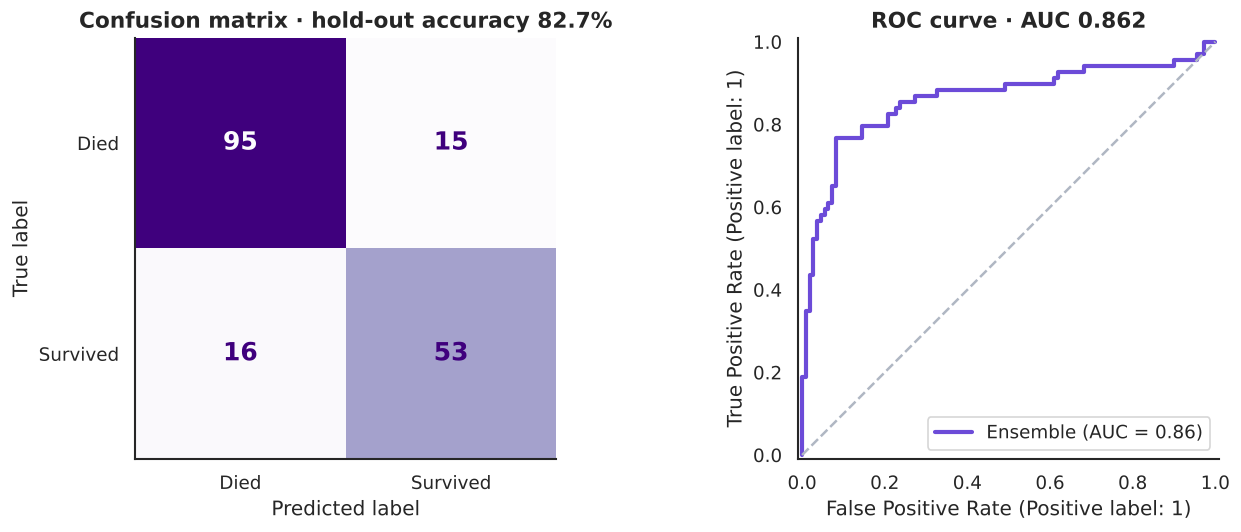

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.6))
ConfusionMatrixDisplay.from_predictions(y_hold, pred, display_labels=['Died', 'Survived'], cmap='Purples',
                                        colorbar=False, ax=axes[0], text_kw={'size': 15, 'weight': 'bold'})
axes[0].set_title(f'Confusion matrix · hold-out accuracy {hold_acc:.1%}')
RocCurveDisplay.from_predictions(y_hold, proba, ax=axes[1], name='Ensemble', curve_kwargs={'color': PALETTE['survived'], 'lw': 2.5})
axes[1].plot([0, 1], [0, 1], ls='--', color=PALETTE['died']); axes[1].set_title(f'ROC curve · AUC {hold_auc:.3f}')
plt.tight_layout(); plt.savefig('images/04_holdout_evaluation.png', bbox_inches='tight'); plt.show()

## 6 · What drives the predictions, and the Kaggle submission

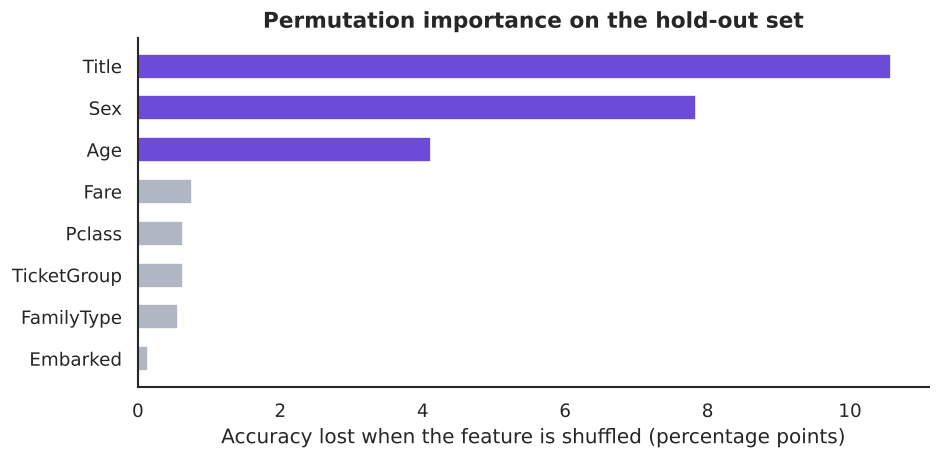

In [12]:
perm = permutation_importance(final, X_hold, y_hold, n_repeats=30, random_state=SEED, scoring='accuracy')
imp = (pd.DataFrame({'Feature': X_hold.columns, 'Drop in accuracy': perm.importances_mean})
       .query('Feature in @CATEGORICAL or Feature in @NUMERIC or Feature == "Fare"')
       .sort_values('Drop in accuracy'))
imp = imp[imp['Drop in accuracy'] > 0.001]
fig, ax = plt.subplots(figsize=(8, 4))
colors = [PALETTE['survived'] if i >= len(imp) - 3 else PALETTE['died'] for i in range(len(imp))]
ax.barh(imp.Feature, imp['Drop in accuracy'] * 100, color=colors, height=0.6)
ax.set_xlabel('Accuracy lost when the feature is shuffled (percentage points)')
ax.set_title('Permutation importance on the hold-out set')
plt.tight_layout(); plt.savefig('images/05_feature_importance.png', bbox_inches='tight'); plt.show()

Permutation importance shuffles one input at a time and measures how much hold-out accuracy drops. Unlike tree-based importance, it works for any model and is not biased toward features with many distinct values.

In [13]:
final.fit(X, y)  # refit on all 891 labelled passengers
submission = pd.DataFrame({'PassengerId': test.PassengerId, 'Survived': final.predict(X_kaggle)})
submission.to_csv('submission.csv', index=False)
print(f'submission.csv written: {len(submission)} rows, predicted survival rate {submission.Survived.mean():.1%}')
submission.head()

submission.csv written: 418 rows, predicted survival rate 38.8%


,PassengerId,Survived
0,892,0
1,893,0
2,894,0
3,895,0
4,896,1


## 7 · Summary

**Who survived?** Being a woman, travelling in first or second class, being a child, or travelling with a small family raised the chance of survival the most. Of all passengers, 74% of women survived against 19% of men, and 97% of first-class women against 14% of third-class men.

**How well does the model predict it?** A soft-voting ensemble of four models predicts survival correctly for about **83% of passengers** in cross-validation, and the hold-out figure above confirms it on passengers the model never saw. That is about 21 points better than guessing that everyone died, and in line with well-built solutions on this dataset. Scores far above 85% on Titanic usually come from leaked labels.

**What I would do next:** submit `submission.csv` to Kaggle for an independent test score, try target-free group features (shared surnames across the passenger list), and calibrate probabilities if they are used for ranking rather than yes/no predictions.

*Data: Kaggle, Titanic: Machine Learning from Disaster (public).*